# 01 — Exploratory Data Analysis

**Goal:** understand the data before modeling. Questions this notebook answers:

1. What does the Vikings' history look like, and how unusual is the 2026 start?
2. How big is home-field advantage, and is it stable over time?
3. How well does the Vegas spread predict winners? (This is the baseline the model has to compete with.)
4. Do pre-game efficiency stats (EPA/play) carry signal for who wins?

Data comes from [nflverse](https://github.com/nflverse) via `python -m vikpred.data.ingest`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from vikpred.data import load

sns.set_theme(style="whitegrid", context="notebook")
VIKINGS_PURPLE, VIKINGS_GOLD = "#4F2683", "#FFC62F"
pd.set_option("display.width", 140)

## 1. Dataset overview

In [2]:
sched = load.schedules()
epa = load.team_game_epa()
inj = load.injuries()

played = sched[sched["result"].notna()]
print(f"Games:       {len(sched):,} ({sched.season.min()}-{sched.season.max()}), {len(played):,} played")
print(f"Team-games:  {len(epa):,} rows of offensive EPA")
print(f"Injury rows: {len(inj):,}")
sched.groupby("game_type").size().rename("games").to_frame().T

Games:       4,635 (2010-2026), 4,458 played
Team-games:  8,914 rows of offensive EPA
Injury rows: 88,070


game_type,CON,DIV,REG,SB,WC
games,32,64,4447,16,76


## 2. The Vikings, 2010 – today

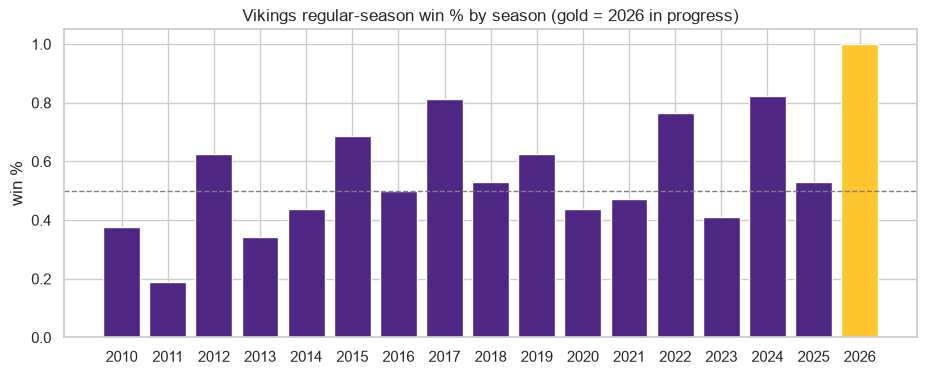

,wins,games,point_diff,win_pct
season,,,,
2021,8.0,17,-1.0,0.470588
2022,13.0,17,-3.0,0.764706
2023,7.0,17,-18.0,0.411765
2024,14.0,17,100.0,0.823529
2025,9.0,17,11.0,0.529412
2026,5.0,5,45.0,1.000000


In [3]:
vik = load.team_games("MIN")
vik_played = vik[vik["win"].notna()]
by_season = (vik_played[vik_played.game_type == "REG"]
             .groupby("season")
             .agg(wins=("win", "sum"), games=("win", "size"), point_diff=("margin", "sum")))
by_season["win_pct"] = by_season.wins / by_season.games

fig, ax = plt.subplots(figsize=(11, 4))
colors = [VIKINGS_GOLD if s == by_season.index.max() else VIKINGS_PURPLE for s in by_season.index]
ax.bar(by_season.index, by_season.win_pct, color=colors)
ax.axhline(0.5, color="grey", ls="--", lw=1)
ax.set(title="Vikings regular-season win % by season (gold = 2026 in progress)", ylabel="win %", xlabel="")
ax.set_xticks(by_season.index)
plt.show()
by_season.tail(6)

### 2026 so far: winning, but how?

In [4]:
# Offense: Vikings' own plays. Defense: opponents' plays against the Vikings.
off = epa[(epa.team == "MIN") & (epa.season == 2026)][["game_id", "epa_per_play", "success_rate"]]
dfn = (epa[(epa.opponent == "MIN") & (epa.season == 2026)][["game_id", "epa_per_play", "success_rate"]]
       .rename(columns={"epa_per_play": "def_epa_allowed", "success_rate": "def_success_allowed"}))
season_2026 = (vik[vik.season == 2026]
               .merge(off, on="game_id", how="left").merge(dfn, on="game_id", how="left"))
season_2026[["week", "opponent", "is_home", "points_for", "points_against", "team_spread",
             "epa_per_play", "def_epa_allowed"]].round(3)

,week,opponent,is_home,points_for,points_against,team_spread,epa_per_play,def_epa_allowed
0,1,GB,True,39.0,22.0,1.5,0.071,-0.181
1,2,CHI,False,9.0,3.0,-4.5,-0.073,-0.138
2,3,TB,False,23.0,16.0,1.5,-0.295,-0.296
3,4,MIA,True,15.0,10.0,10.0,-0.056,-0.240
4,5,NO,False,23.0,13.0,2.5,-0.157,-0.374
5,7,IND,True,NaN,NaN,6.5,NaN,NaN
6,8,DET,False,NaN,NaN,NaN,NaN,NaN
7,9,BUF,True,NaN,NaN,NaN,NaN,NaN
8,10,GB,False,NaN,NaN,NaN,NaN,NaN
9,11,SF,False,NaN,NaN,NaN,NaN,NaN


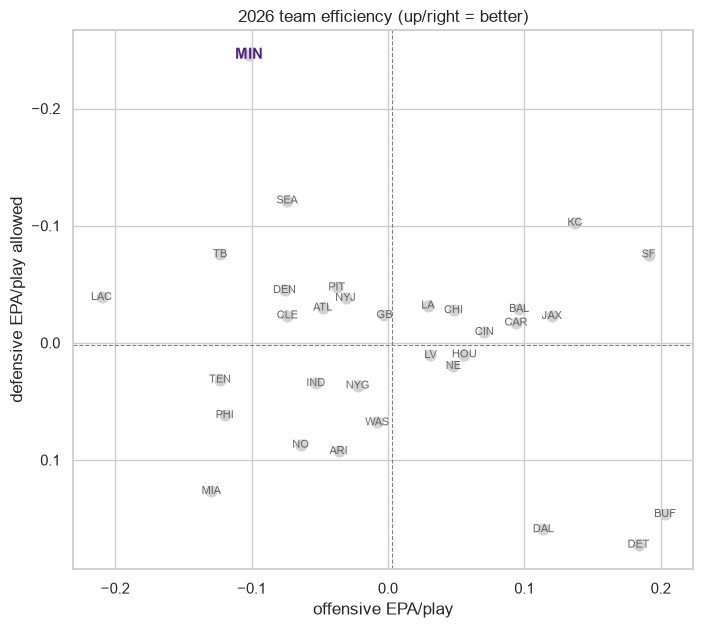

,off_epa,def_epa_allowed,off_rank,def_rank
MIN,-0.102,-0.246,27,1


In [5]:
# Where do the Vikings rank league-wide in 2026 (offense and defense EPA/play)?
e26 = epa[epa.season == 2026]
league = pd.DataFrame({
    "off_epa": e26.groupby("team").epa_per_play.mean(),
    "def_epa_allowed": e26.groupby("opponent").epa_per_play.mean(),
})
league["off_rank"] = league.off_epa.rank(ascending=False).astype(int)
league["def_rank"] = league.def_epa_allowed.rank().astype(int)

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(league.off_epa, league.def_epa_allowed, color="lightgrey", s=60)
for team, r in league.iterrows():
    is_min = team == "MIN"
    ax.annotate(team, (r.off_epa, r.def_epa_allowed), fontsize=11 if is_min else 8,
                fontweight="bold" if is_min else "normal",
                color=VIKINGS_PURPLE if is_min else "dimgrey", ha="center", va="center")
ax.invert_yaxis()  # lower EPA allowed = better defense, so up is good
ax.axvline(league.off_epa.mean(), color="grey", lw=0.8, ls="--")
ax.axhline(league.def_epa_allowed.mean(), color="grey", lw=0.8, ls="--")
ax.set(title="2026 team efficiency (up/right = better)", xlabel="offensive EPA/play",
       ylabel="defensive EPA/play allowed")
plt.show()
league.loc[["MIN"]].round(3)

## 3. Home-field advantage over time

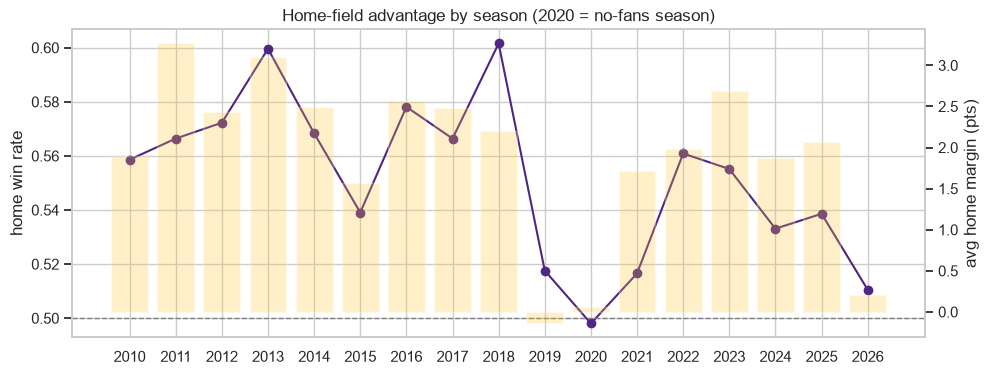

season,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
home_win_rate,0.559,0.566,0.572,0.600,0.568,0.539,0.578,0.566,0.602,0.518,0.498,0.517,0.561,0.555,0.533,0.539,0.511
avg_home_margin,1.895,3.266,2.434,3.105,2.488,1.562,2.566,2.484,2.203,-0.141,0.055,1.713,1.978,2.684,1.868,2.070,0.211


In [6]:
reg = played[played.game_type == "REG"]
hfa = reg.groupby("season").agg(home_win_rate=("home_win", "mean"), avg_home_margin=("result", "mean"))

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.plot(hfa.index, hfa.home_win_rate, marker="o", color=VIKINGS_PURPLE, label="home win rate")
ax1.axhline(0.5, color="grey", ls="--", lw=1)
ax1.set(ylabel="home win rate", title="Home-field advantage by season (2020 = no-fans season)")
ax2 = ax1.twinx()
ax2.bar(hfa.index, hfa.avg_home_margin, alpha=0.25, color=VIKINGS_GOLD, label="avg home margin")
ax2.set_ylabel("avg home margin (pts)")
ax2.grid(False)
ax1.set_xticks(hfa.index)
plt.show()
hfa.round(3).T

## 4. How good is Vegas?

`spread_line` is the home team's expected margin of victory. If the spread is well calibrated, the home team's win rate should rise smoothly as the spread grows. This is the **baseline our model must compete with**.

Favorite won 66.5% of 4,252 regular-season games
Home team won 55.3% (the naive 'always pick home' baseline)


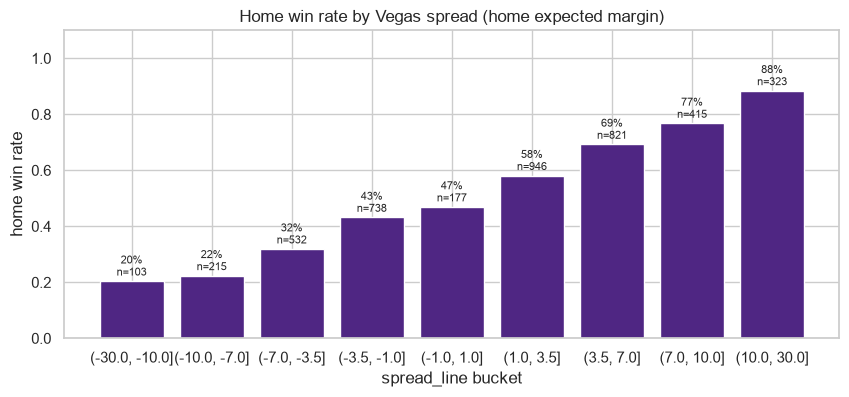

In [7]:
reg = reg.assign(fav_won=np.where(reg.spread_line == 0, np.nan,
                                  (np.sign(reg.spread_line) == np.sign(reg.result)).astype(float)))
reg.loc[reg.result == 0, "fav_won"] = np.nan  # ties
print(f"Favorite won {reg.fav_won.mean():.1%} of {reg.fav_won.notna().sum():,} regular-season games")
print(f"Home team won {reg.home_win.mean():.1%} (the naive 'always pick home' baseline)")

bins = [-30, -10, -7, -3.5, -1, 1, 3.5, 7, 10, 30]
cal = (reg.assign(spread_bucket=pd.cut(reg.spread_line, bins))
       .groupby("spread_bucket", observed=True)
       .agg(games=("home_win", "size"), home_win_rate=("home_win", "mean")))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(cal.index.astype(str), cal.home_win_rate, color=VIKINGS_PURPLE)
for i, (rate, n) in enumerate(zip(cal.home_win_rate, cal.games)):
    ax.text(i, rate + 0.02, f"{rate:.0%}\nn={n}", ha="center", fontsize=8)
ax.set(title="Home win rate by Vegas spread (home expected margin)", xlabel="spread_line bucket",
       ylabel="home win rate", ylim=(0, 1.1))
plt.show()

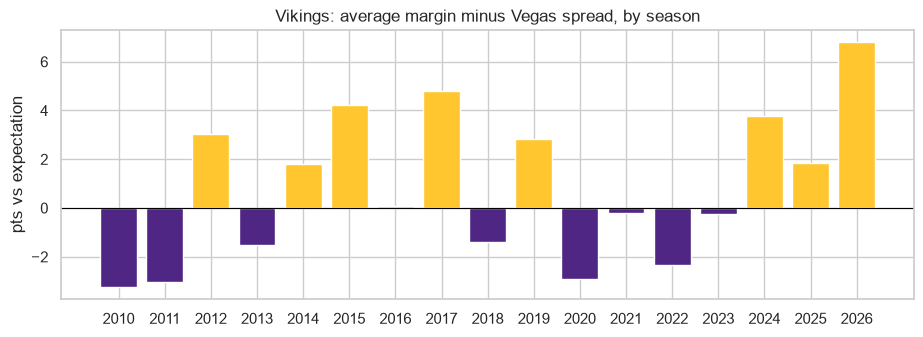

In [8]:
# How have the Vikings done relative to the spread? (positive = beat expectations)
vik_played = vik_played.assign(vs_spread=vik_played.margin - vik_played.team_spread)
ats = vik_played[vik_played.game_type == "REG"].groupby("season").vs_spread.mean()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(ats.index, ats, color=[VIKINGS_GOLD if v > 0 else VIKINGS_PURPLE for v in ats])
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Vikings: average margin minus Vegas spread, by season", ylabel="pts vs expectation")
ax.set_xticks(ats.index)
plt.show()

## 5. Do pre-game efficiency stats predict winners?

Preview of Phase 2 features. For each team-game, take the team's **average EPA/play over its previous 4 games** (using `shift(1)` so the current game is never included, which would be data leakage). Then compare the home and away teams' pre-game numbers.

3,724 games with pre-game EPA for both teams
              net_epa_diff  spread_line  result
net_epa_diff         1.000        0.700   0.301
spread_line          0.700        1.000   0.439
result               0.301        0.439   1.000


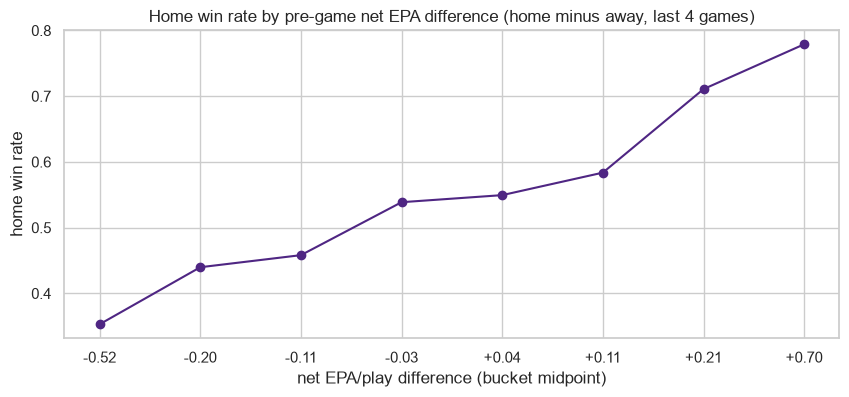

In [9]:
def pregame_rolling(epa: pd.DataFrame, window: int = 4) -> pd.DataFrame:
    # Offense = own EPA; defense = opponent's EPA when facing this team.
    off = epa[["game_id", "season", "week", "team", "epa_per_play"]]
    dfn = (epa[["game_id", "opponent", "epa_per_play"]]
           .rename(columns={"opponent": "team", "epa_per_play": "def_epa_allowed"}))
    g = off.merge(dfn, on=["game_id", "team"]).sort_values(["team", "season", "week"])
    for col in ["epa_per_play", "def_epa_allowed"]:
        g[f"pre_{col}"] = (g.groupby(["team", "season"])[col]
                            .transform(lambda s: s.shift(1).rolling(window, min_periods=2).mean()))
    g["pre_net_epa"] = g.pre_epa_per_play - g.pre_def_epa_allowed
    return g[["game_id", "team", "pre_net_epa"]]

roll = pregame_rolling(epa)
games = (reg.merge(roll.rename(columns={"team": "home_team", "pre_net_epa": "home_pre"}), on=["game_id", "home_team"])
            .merge(roll.rename(columns={"team": "away_team", "pre_net_epa": "away_pre"}), on=["game_id", "away_team"])
            .dropna(subset=["home_pre", "away_pre"]))
games["net_epa_diff"] = games.home_pre - games.away_pre

print(f"{len(games):,} games with pre-game EPA for both teams")
print(games[["net_epa_diff", "spread_line", "result"]].corr().round(3))

games["epa_bucket"] = pd.qcut(games.net_epa_diff, 8)
eb = games.groupby("epa_bucket", observed=True).home_win.mean()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(len(eb)), eb.values, marker="o", color=VIKINGS_PURPLE)
ax.set_xticks(range(len(eb)), [f"{i.mid:+.2f}" for i in eb.index])
ax.set(title="Home win rate by pre-game net EPA difference (home minus away, last 4 games)",
       xlabel="net EPA/play difference (bucket midpoint)", ylabel="home win rate")
plt.show()

## 6. Injury reports at a glance

In [10]:
print(inj.columns.tolist())
inj[inj.season == inj.season.max()].groupby("report_status").size().sort_values(ascending=False).head(8)

['season', 'game_type', 'team', 'week', 'gsis_id', 'position', 'full_name', 'first_name', 'last_name', 'report_primary_injury', 'report_secondary_injury', 'report_status', 'practice_primary_injury', 'practice_secondary_injury', 'practice_status', 'date_modified', 'season_type']


report_status
Out             463
Questionable    438
Doubtful         34
dtype: int64

## Takeaways for Phase 2

1. **The 2026 Vikings are a defense-first team.** Through 5 games they rank **1st in defensive EPA/play allowed (-0.246)** but **27th in offensive EPA/play (-0.102)**. They are also beating the Vegas spread by ~7 pts/game, the most of any season since 2010. Five games is a small sample, so expect some regression; the model should weight early-season stats with care.
2. **Vegas sets a high bar.** The spread favorite wins **66.5%** of regular-season games, versus **55.3%** for "always pick the home team." Phase 2 will measure the model against both, using log loss and Brier score rather than accuracy alone.
3. **Home-field advantage is real but shrinking.** It went from ~57% home win rate in the 2010s to ~52-54% recently (and ~50% in the 2020 no-fans season). Treat it as a learned feature, possibly season-weighted, not a fixed bonus.
4. **Pre-game EPA carries signal, but Vegas already uses most of it.** Rolling net EPA difference correlates **0.30** with the final margin (spread: **0.44**), and **0.70** with the spread itself. The most realistic goal is a model that *combines* the market line with efficiency, rest, QB, and injury features and stays well calibrated, not one that beats Vegas outright.
5. **Leakage guardrails work.** Rolling features use `shift(1)`, so a game's own stats never feed its prediction. Phase 2 will add a test that enforces this.

**Phase 2 feature candidates:** spread & total line, rolling offensive/defensive EPA and success rate (pass/rush split), rest days, home/away & division game, starting QB change, count of key starters ruled Out, weather/roof.